# Aura of Despair (Seyan'Du)

Aura of Despair (`SK_AURA_CURSE`, "Curse Aura" in the server) is a toggled aura. Once a second it
applies a 2 s curse to every character within 12 tiles whose group differs from the caster's. The
curse lowers all five attributes, and therefore every skill. A character can run only one aura
at a time; switching replaces the active one.

| | |
|---|---|
| Class | Seyan'Du (talent "Aura of Despair") |
| Target | Every visible, living character in the 25×25 square whose `data[CHD_GROUP]` differs from the caster's |
| Cost | none: no mana, endurance or upkeep |
| Cooldown | none; toggled on and off with the skill |
| Landing roll | none: no resist roll, no Immunity reduction, no race modifier |
| Duration | permanent while toggled; each pulse applies or refreshes a 2 s item |
| Effect | `power = 50 + ⌊p/2⌋`; `attrib[n][1] = −⌊power/3⌋` for all five attributes |
| Source | `server/src/aura/mod.rs` (`aura_power`, `apply_modifiers`, `is_valid_target`); `server/src/aura/logic.rs`; `server/src/driver/skill/auras.rs::skill_curse_aura` |

---

# Formula

With $p$ the caster's modified skill:

$$
\text{power} = 50 + \lfloor p/2 \rfloor
\qquad
\Delta\text{attribute} = -\left\lfloor \frac{\text{power}}{3} \right\rfloor
\qquad
\Delta\text{skill} \approx -\left\lfloor \frac{3\,\lfloor\text{power}/3\rfloor}{5} \right\rfloor
$$

Every skill gets ⌊(sum of its three attributes)/5⌋, so each skill drops by about ⅗ of the
attribute penalty (±1 from rounding). The stock Curse spell, for comparison:

$$
\Delta\text{attribute}_\text{Curse} = -\left\lfloor \frac{\text{race}(\text{immunity}(p))}{3} \right\rfloor
\qquad
P(\text{lands}) = \frac{\operatorname{clamp}\!\left(\lfloor 10p/R_\text{eff}\rfloor,\ 0,\ 18\right) + 1}{20}
$$

Curse costs 35 mana, has a 4 s exhaust and lasts 120 s. It uses a different temp, so a cursed
target can carry both penalties at once. When two auras of the same kind overlap, the strictly
stronger one replaces the weaker; equal ones do not fight.

| Quantity | Breakpoint |
|---|---|
| At skill 0 | −16 attributes (power 50) |
| At the raise caps | −34 at 105, −36 at 120 |
| Ceiling | none: −1 per 6 skill points |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
BASE_POWER = 50
RADIUS = 12
CURSE_RACE = "Seyan'Du"

# Model

In [2]:
def aura_power(p):
    return np.maximum(1, BASE_POWER + mm.idiv(p, 2))


def aura_penalty(p):
    return mm.idiv(aura_power(p), 3)


def curse_penalty(p, immun=0, race=CURSE_RACE):
    return mm.idiv(mm.spell_power(p, immun, race), 3)


def curse_expected(p, immun=0, resist=50, race=CURSE_RACE):
    return mm.p_chance_base(p, 10, resist) * curse_penalty(p, immun, race)


def skill_drop(penalty, attrib_sum=3 * 60):
    """Drop of a skill whose three attributes sum to `attrib_sum` (attributes floor at 1)."""
    after = np.maximum(1, attrib_sum // 3 - np.asarray(penalty)) * 3
    return attrib_sum // 5 - after // 5


def enemy_hit_chance(p, enemy_ws=100, defender_ws=100):
    """P(cursed enemy lands a normal hit) on a defender with equal Weapon Skill."""
    ws = enemy_ws - skill_drop(aura_penalty(p))
    return np.array([mm.p_melee_hit(int(d)) for d in np.atleast_1d(ws - defender_ws)])

# Validation

- `curse_aura_power_scales_with_skill_total`: power and penalty grow from total 1 to total 100.
- `curse_aura_does_not_apply_to_caster`, `curse_aura_toggles_on_and_off`,
  `switching_auras_replaces_the_active_one`.
- `spell_curse_lowers_every_attribute_by_a_third_of_power` and
  `spell_curse_power_is_reduced_by_target_immunity` (Curse, for the comparison): power 30 → −10;
  with Immunity, power 20 → −6.

In [3]:
assert aura_power(1) == 50 and aura_power(100) == 100 and aura_penalty(1) < aura_penalty(100)
assert aura_penalty(0) == 16 and aura_penalty(105) == 34 and aura_penalty(120) == 36
assert mm.idiv(30, 3) == 10 and mm.idiv(20, 3) == 6
assert mm.TICKS * 2 == 72
print("Aura of Despair model OK")

Aura of Despair model OK


# Plots

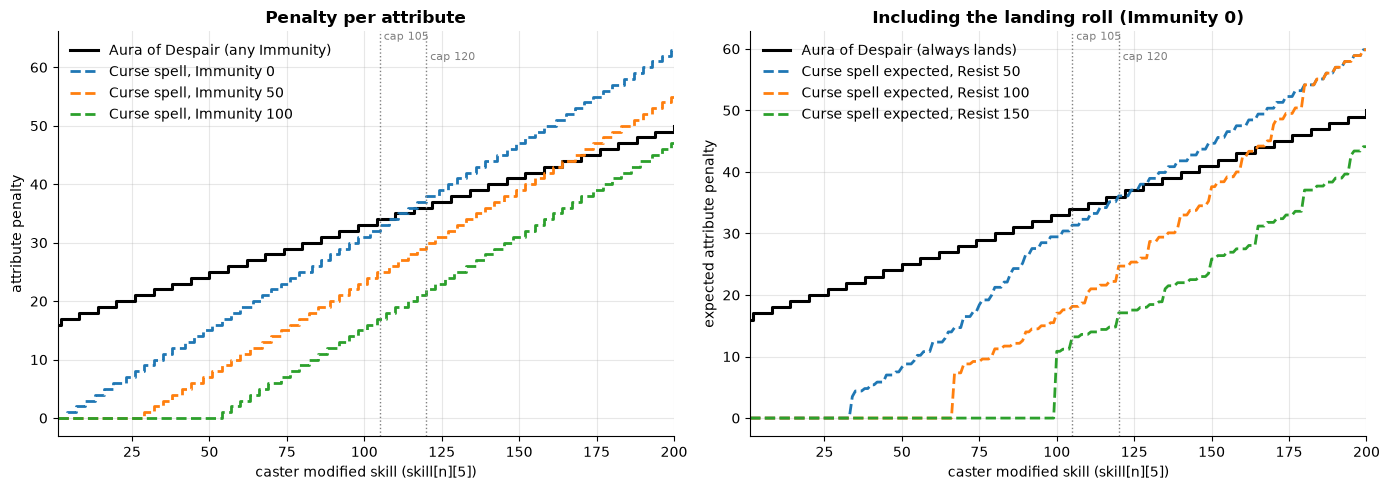

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.step(P, aura_penalty(P), where="post", color="black", lw=2.2, label="Aura of Despair (any Immunity)")
for imm in (0, 50, 100):
    ax.step(P, curse_penalty(P, imm), where="post", ls="--", label=f"Curse spell, Immunity {imm}")
mm.skill_axis(ax, "attribute penalty", "Penalty per attribute")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
ax.step(P, aura_penalty(P), where="post", color="black", lw=2.2, label="Aura of Despair (always lands)")
for r in (50, 100, 150):
    ax.plot(P, curse_expected(P, 0, r), ls="--", label=f"Curse spell expected, Resist {r}")
mm.skill_axis(ax, "expected attribute penalty", "Including the landing roll (Immunity 0)")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

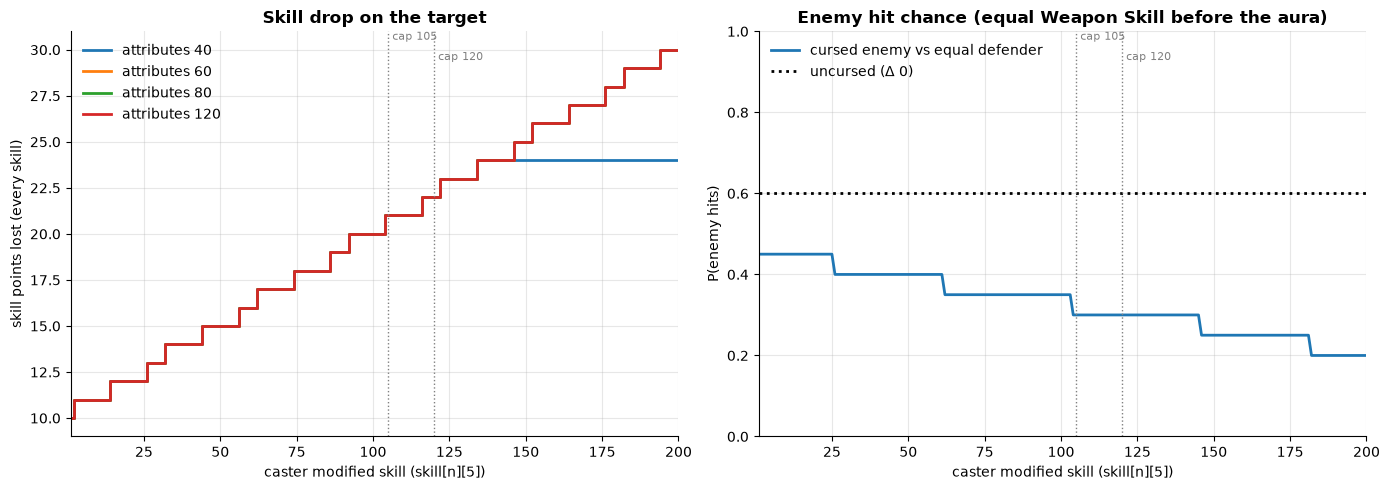

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for s in (40, 60, 80, 120):
    ax.step(P, skill_drop(aura_penalty(P), 3 * s), where="post", label=f"attributes {s}")
mm.skill_axis(ax, "skill points lost (every skill)", "Skill drop on the target")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
ax.plot(P, enemy_hit_chance(P), label="cursed enemy vs equal defender")
ax.axhline(mm.p_melee_hit(0), color="black", ls=":", label="uncursed (Δ 0)")
mm.skill_axis(ax, "P(enemy hits)", "Enemy hit chance (equal Weapon Skill before the aura)")
ax.set_ylim(0, 1)
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

# Observations

- **Free, permanent and unavoidable.** There is no mana or endurance cost, no upkeep, no roll and
  no Immunity reduction. At skill 105 every enemy within 12 tiles loses 34 from every attribute,
  which is 20–21 from every skill. The stock Curse spell at the same skill gives −33 against
  Immunity 0, −25 against 50 and −17 against 100, and only lands 95% / 55% / 40% of the time
  against Resist 50 / 100 / 150. It also costs 35 mana per cast.
- **It does not saturate.** Unlike most of the new abilities it gains −1 per 6 points over the
  whole range, and it starts high: skill 0 already gives −16 (power 50).
- **It stacks with Curse.** The temps differ (`SK_AURA_CURSE` vs `SK_CURSE`), so a target hit by
  both loses 34 + 33 = 67 per attribute at skill 105.
- **It weakens resistance to the caster's other spells.** Resist and Immunity drop with every other
  skill, so the target's defence against every other spell falls by about 20 points before any
  roll.
- **An even melee fight turns.** A cursed enemy with equal Weapon Skill hits 30% of the time
  instead of 60% (Δ −20). Its own Strength-driven damage, HP and speed drop as well.
- **Targeting is by group only.** `is_valid_target` checks that the target's `data[CHD_GROUP]`
  differs from the caster's, and skips bodies and invisible characters. It does **not** call
  `may_aoe_attack`, check line of sight, or notify the target. Ghost companions use group
  `65536 + owner`, so the caster's **own ghosts are cursed** (−34 on a companion with 114
  attributes). Shopkeepers, guards and players in other groups are cursed silently as well,
  with no aggro and no PvP check.
- **The description undersells it.** "A minor curse aura" is a debuff that, at skill 105, beats a
  full Curse cast on most targets.
- **Balance suggestions.** Start at power 0 and run it through `spell_immunity`, for example
  `−(p/2)/3` after Immunity (−17 at 105). Add an upkeep (mana or endurance per second). Use
  `may_aoe_attack` for target selection, and skip the caster's own companions.